In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from keras.preprocessing.text import Tokenizer
from keras.utils import pad_sequences
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout
from keras.optimizers import Adam
import joblib

In [2]:
df = pd.read_csv('train-balanced-sarcasm.csv')

In [3]:
df

,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...
...,...,...,...,...,...,...,...,...,...,...
1010821,1,I'm sure that Iran and N. Korea have the techn...,TwarkMain,reddit.com,2,2,0,2009-04,2009-04-25 00:47:52,"No one is calling this an engineered pathogen,..."
1010822,1,"whatever you do, don't vote green!",BCHarvey,climate,1,1,0,2009-05,2009-05-14 22:27:40,In a move typical of their recent do-nothing a...
1010823,1,Perhaps this is an atheist conspiracy to make ...,rebelcommander,atheism,1,1,0,2009-01,2009-01-11 00:22:57,Screw the Disabled--I've got to get to Church ...
1010824,1,The Slavs got their own country - it is called...,catsi,worldnews,1,1,0,2009-01,2009-01-23 21:12:49,I've always been unsettled by that. I hear a l...


In [4]:
# List of all column names
print(df.columns)

Index(['label', 'comment', 'author', 'subreddit', 'score', 'ups', 'downs',
       'date', 'created_utc', 'parent_comment'],
      dtype='object')


In [5]:
df.isnull().sum()

label              0
comment           55
author             0
subreddit          0
score              0
ups                0
downs              0
date               0
created_utc        0
parent_comment     0
dtype: int64

In [6]:
df.duplicated().sum()

28

In [7]:
# Remove rows with null values in the 'comment' column
df = df.dropna(subset=['comment'])

# Optionally, reset the index after dropping rows
df = df.reset_index(drop=True)



In [8]:
df

,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...
...,...,...,...,...,...,...,...,...,...,...
1010766,1,I'm sure that Iran and N. Korea have the techn...,TwarkMain,reddit.com,2,2,0,2009-04,2009-04-25 00:47:52,"No one is calling this an engineered pathogen,..."
1010767,1,"whatever you do, don't vote green!",BCHarvey,climate,1,1,0,2009-05,2009-05-14 22:27:40,In a move typical of their recent do-nothing a...
1010768,1,Perhaps this is an atheist conspiracy to make ...,rebelcommander,atheism,1,1,0,2009-01,2009-01-11 00:22:57,Screw the Disabled--I've got to get to Church ...
1010769,1,The Slavs got their own country - it is called...,catsi,worldnews,1,1,0,2009-01,2009-01-23 21:12:49,I've always been unsettled by that. I hear a l...


In [9]:
# Remove duplicate rows from the entire dataset
df = df.drop_duplicates()

# Optionally, reset the index after removing duplicates
df = df.reset_index(drop=True)

In [10]:
df

,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...
...,...,...,...,...,...,...,...,...,...,...
1010738,1,I'm sure that Iran and N. Korea have the techn...,TwarkMain,reddit.com,2,2,0,2009-04,2009-04-25 00:47:52,"No one is calling this an engineered pathogen,..."
1010739,1,"whatever you do, don't vote green!",BCHarvey,climate,1,1,0,2009-05,2009-05-14 22:27:40,In a move typical of their recent do-nothing a...
1010740,1,Perhaps this is an atheist conspiracy to make ...,rebelcommander,atheism,1,1,0,2009-01,2009-01-11 00:22:57,Screw the Disabled--I've got to get to Church ...
1010741,1,The Slavs got their own country - it is called...,catsi,worldnews,1,1,0,2009-01,2009-01-23 21:12:49,I've always been unsettled by that. I hear a l...


In [11]:
df.isnull().sum()

label             0
comment           0
author            0
subreddit         0
score             0
ups               0
downs             0
date              0
created_utc       0
parent_comment    0
dtype: int64

In [12]:
df.duplicated().sum()

0

In [13]:
X = df['comment']  
y = df['label'] 

In [14]:
X

0                                                 NC and NH.
1          You do know west teams play against west teams...
2          They were underdogs earlier today, but since G...
3          This meme isn't funny none of the "new york ni...
4                            I could use one of those tools.
                                 ...                        
1010738    I'm sure that Iran and N. Korea have the techn...
1010739                   whatever you do, don't vote green!
1010740    Perhaps this is an atheist conspiracy to make ...
1010741    The Slavs got their own country - it is called...
1010742    values, as in capitalism .. there is good mone...
Name: comment, Length: 1010743, dtype: object

In [15]:
y

0          0
1          0
2          0
3          0
4          0
          ..
1010738    1
1010739    1
1010740    1
1010741    1
1010742    1
Name: label, Length: 1010743, dtype: int64

In [16]:
# Count the number of occurrences of each class (0 and 1) in the 'sentiment' column
class_counts = y.value_counts()

# Print the counts for class 0 and class 1
print(f"Class 0 sentiment count: {class_counts.get(0, 0)}")
print(f"Class 1 sentiment count: {class_counts.get(1, 0)}")



Class 0 sentiment count: 505403
Class 1 sentiment count: 505340


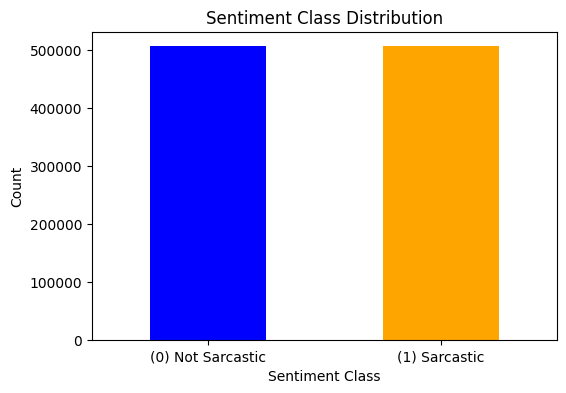

In [17]:
import matplotlib.pyplot as plt

# Count the occurrences of each class (0 and 1) in the 'sentiment' column
class_counts = y.value_counts()

# Reindex to ensure that both classes 0 and 1 are represented (in case one class is missing)
class_counts = class_counts.reindex([0, 1], fill_value=0)

# Create a bar plot
plt.figure(figsize=(6, 4))  # Set the size of the plot
class_counts.plot(kind='bar', color=['blue', 'orange'])  # Plot the bar chart

# Set title and labels
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment Class')
plt.ylabel('Count')

# Change x-tick labels to show "Not Sarcastic" and "Sarcastic"
plt.xticks(ticks=[0, 1], labels=['(0) Not Sarcastic', '(1) Sarcastic'], rotation=0)

# Show the plot
plt.show()


In [18]:
max_words = 10000  
max_len = 100  

In [19]:
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X)  

In [20]:
X_seq = tokenizer.texts_to_sequences(X)

In [21]:
X_padded = pad_sequences(X_seq, maxlen=max_len)

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X_padded, y, test_size=0.2, random_state=42)

In [23]:
model = Sequential()

In [24]:
model.add(Embedding(input_dim=max_words, output_dim=100, input_length=max_len))


In [25]:
model.add(LSTM(100, dropout=0.2, recurrent_dropout=0.2))

In [26]:
model.add(Dense(3, activation='softmax')) 

In [27]:
model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [28]:
history = model.fit(X_train, y_train, epochs=255, batch_size=64, validation_data=(X_test, y_test), callbacks=[early_stopping])
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_test, y_test))

Epoch 1/5
12635/12635 [==============================] - 2284s 181ms/step - loss: 0.5629 - accuracy: 0.7053 - val_loss: 0.5443 - val_accuracy: 0.7216
Epoch 2/5
12635/12635 [==============================] - 2367s 187ms/step - loss: 0.5303 - accuracy: 0.7311 - val_loss: 0.5393 - val_accuracy: 0.7246
Epoch 3/5
12635/12635 [==============================] - 2257s 179ms/step - loss: 0.5151 - accuracy: 0.7424 - val_loss: 0.5388 - val_accuracy: 0.7259
Epoch 4/5
12635/12635 [==============================] - 2315s 183ms/step - loss: 0.5015 - accuracy: 0.7513 - val_loss: 0.5450 - val_accuracy: 0.7247
Epoch 5/5
12635/12635 [==============================] - 2345s 186ms/step - loss: 0.4886 - accuracy: 0.7607 - val_loss: 0.5465 - val_accuracy: 0.7253


In [29]:
model.save('lstm_model.h5') 

joblib.dump(tokenizer, 'tokenizer.pkl')


C:\Users\Python1\anaconda3\envs\Naveen\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


['tokenizer.pkl']

In [30]:
print("Model and tokenizer saved successfully!")

Model and tokenizer saved successfully!


In [31]:
# Optionally, print training history for evaluation
#print("Training History: ", history.history)


In [32]:
print(f"Final Training Accuracy: {history.history['accuracy'][-1]:.4f}")
#print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")


Final Training Accuracy: 0.7607
